##ЛР3. Задача классификации

[12 баллов]

## О формате сдачи (все ЛР)

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, могут помечаться фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, могут помечаться фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

Выполнил **Данилов Тимофей, P3331**. Совместная работа с Романом Пивоваровым.
Выполнены только задания **1, 2 и 4 (6 из 12 баллов)**. Задание 3 оставлено Роману.
Из предложенного выбора «3.1 или 4» выбран пункт 4.
Данные: [Real Estate Listings in Portugal](https://www.kaggle.com/datasets/luvathoms/portugal-real-estate-2024), снимок из ЛР1–2.
Запускать все ячейки последовательно из папки lab3 либо корня репозитория.

## Этапы

<font color='DarkOrange'>**Задание 1 [баллов: 2]:**</font>

Выберите датасет и задачу для него (классификация) - с Kaggle или UCI Machine Learning Repository (https://archive.ics.uci.edu/datasets).
Важно: используйте более новые датасеты, кол-во объектов не менее 100.
Лучше воспользоваться датасетом из предыдущих ЛР.

Выберите (или сгенерите сами) признак, который будет целевым для бинарной классификации.

Используйте LogisticRegression из sklearn. Задайте несколько параметров метода самостоятельно, поясните их назначение и причину выбора конкретных значений.
Используйте несколько метрик, чтоб оценить результаты бинарной классификации (метрики, доступные в sklearn).

### Постановка задачи
Класс 1 — дорогая квартира: **Price ≥ 500 000 €**, класс 0 — остальные квартиры. Это заранее выбранная учебная граница ценового сегмента, а не квантиль test. По площади, санузлам, году, парковке, лифту, сертификату, округу и городу предсказываем сегмент.
Цена и производные цены исключены из X. Полные дубликаты удаляем до разбиения. Используем фиксированные предметные ограничения из ЛР1: квартиры с 01.07.2025, площадь 10–1000 м², цена 10 тыс.–20 млн €.
В отличие от ЛР1–2, строки с пропусками признаков сохраняем: медианы и категории для заполнения вычисляются внутри Pipeline на обучающем фолде. Это **новое разбиение для классификации**, размеры не обязаны совпадать с регрессионными ЛР1–2. Test 20%, стратификация по классу; подбор моделей только на train.
Случайный hold-out оценивает похожие объявления, не перенос на будущий рынок. Без ID недвижимости нельзя исключить разные объявления об одном объекте.

,n,expensive,expensive_share
train,13832,3221,0.232866
test,3458,805,0.232794


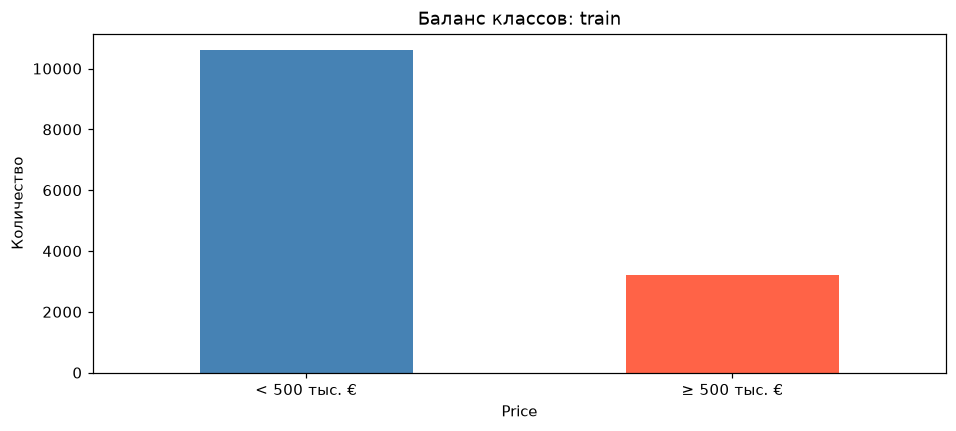

In [1]:
from pathlib import Path
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, OneClassSVM
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('error', category=ConvergenceWarning)
ROOT = Path.cwd() if (Path.cwd()/'lab1').exists() else Path.cwd().parent
OUT = ROOT/'lab3/results'
OUT.mkdir(parents=True, exist_ok=True)
SEED, THRESHOLD = 67, 500_000
NUM = ['LivingArea', 'NumberOfBathrooms', 'ConstructionYear', 'Parking', 'Elevator']
CAT = ['EnergyCertificate', 'District', 'City']
FEATURES = NUM + CAT
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110})
pd.set_option('display.max_columns', 20)
path = ROOT/'lab1/data/portugal_listinigs.csv'
raw = pd.read_csv(path, low_memory=False)
df = raw.drop_duplicates().copy()
df['PublishDate'] = pd.to_datetime(df['PublishDate'], errors='coerce')
df['Elevator'] = df['Elevator'].map({True: 1., False: 0., 'True': 1., 'False': 0.})
df = df.loc[(df['Type']=='Apartment') & (df['PublishDate'] >= '2025-07-01') &
    df['LivingArea'].between(10,1000) & df['Price'].between(10_000,20_000_000)].copy()
for col, lo, hi in [('NumberOfBathrooms',0,10),('ConstructionYear',1900,2026),('Parking',0,20)]:
    df.loc[~df[col].between(lo,hi),col] = np.nan
df['EnergyCertificate'] = df['EnergyCertificate'].replace({'No Certificate':'NC','Not available':'NC'})
# pandas string columns are converted to object with np.nan for sklearn imputers.
for col in CAT:
    df[col] = df[col].astype(object).where(df[col].notna(), np.nan)
y = (df.Price >= THRESHOLD).astype(int)
train_idx, test_idx = train_test_split(df.index, test_size=.2, random_state=SEED, stratify=y)
X_train, X_test = df.loc[train_idx,FEATURES], df.loc[test_idx,FEATURES]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
assert set(train_idx).isdisjoint(test_idx) and 'Price' not in FEATURES and len(df)>=100
assert set(y_train)==set(y_test)=={0,1}
display(pd.DataFrame({'n':[len(y_train),len(y_test)], 'expensive':[y_train.sum(),y_test.sum()],
    'expensive_share':[y_train.mean(),y_test.mean()]}, index=['train','test']))
pd.Series({'csv_sha256':hashlib.sha256(path.read_bytes()).hexdigest(), 'random_state':SEED,
    'threshold':THRESHOLD,'n_train':len(y_train),'n_test':len(y_test)}).to_json(OUT/'data_summary.json',indent=2)
pd.DataFrame({'row_index':df.index,'split':np.where(df.index.isin(train_idx),'train','test'),
    'target':y.to_numpy()}).to_csv(OUT/'split.csv',index=False)
y_train.value_counts().sort_index().plot.bar(color=['steelblue','tomato'])
plt.xticks([0,1],['< 500 тыс. €','≥ 500 тыс. €'],rotation=0)
plt.title('Баланс классов: train'); plt.ylabel('Количество'); plt.show()

### LogisticRegression и оценивание
Модель задаёт P(y=1|x)=sigmoid(wᵀx+b) и минимизирует log-loss с L2-регуляризацией.
`solver='lbfgs'` — оптимизатор для гладкой L2-задачи, `max_iter=3000` — запас итераций, `tol=1e-4` — точность остановки. `class_weight='balanced'` задаёт веса n/(2·n_k), увеличивая штраф за ошибки редкого класса. Они пересчитываются в каждом fit. C — обратная сила регуляризации: меньше C — сильнее регуляризация.
Выбираем C из {0.01, 0.1, 1} по **balanced accuracy** на трёх стратифицированных фолдах train. Все преобразования обучаются внутри CV: заполнение, log площади, масштабирование, One-Hot с объединением категорий частоты <30. Test не участвует в подборе.
Оцениваем accuracy, balanced accuracy, precision, recall, F1, ROC AUC и AP. Для последних двух нужны непрерывные score. AP — сумма precision, взвешенная приростом recall, не трапецеидальная PR AUC. Порог LogisticRegression — 0.5; с весами вероятности могут быть некалиброваны. Сравниваем с константным baseline.

In [2]:
def log_area(a):
    a=np.array(a,dtype=float,copy=True)
    a[:,0]=np.log(a[:,0])
    return a

def preprocessor():
    return ColumnTransformer([
        ('num',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),
            ('log',FunctionTransformer(log_area)),('scale',StandardScaler())]),NUM),
        ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
            ('onehot',OneHotEncoder(handle_unknown='ignore',min_frequency=30))]),CAT)])
folds=list(StratifiedKFold(3,shuffle=True,random_state=SEED).split(X_train,y_train))
MODELS, RESULTS = {}, {}
def fit_search(name,estimator):
    search=GridSearchCV(Pipeline([('prep',preprocessor()),('model',estimator)]),
        {'model__C':[.01,.1,1.]},cv=folds,n_jobs=2,error_score='raise',
        scoring={'balanced_accuracy':'balanced_accuracy','roc_auc':'roc_auc','f1':'f1'},
        refit='balanced_accuracy')
    search.fit(X_train,y_train)
    table=pd.DataFrame(search.cv_results_)[['param_model__C','mean_test_balanced_accuracy',
        'std_test_balanced_accuracy','mean_test_roc_auc','mean_test_f1','rank_test_balanced_accuracy']]
    display(table); table.to_csv(OUT/(name+'_cv.csv'),index=False)
    MODELS[name]=search.best_estimator_
    print(name,search.best_params_)
    return search
lr_search=fit_search('LogisticRegression',LogisticRegression(solver='lbfgs',class_weight='balanced',
    max_iter=3000,tol=1e-4,random_state=SEED))

def evaluate(name,model):
    pred=model.predict(X_test)
    score=model.decision_function(X_test) if hasattr(model,'decision_function') else model.predict_proba(X_test)[:,1]
    RESULTS[name]={'accuracy':accuracy_score(y_test,pred),'balanced_accuracy':balanced_accuracy_score(y_test,pred),
        'precision':precision_score(y_test,pred,zero_division=0),'recall':recall_score(y_test,pred),
        'f1':f1_score(y_test,pred),'roc_auc':roc_auc_score(y_test,score),'AP':average_precision_score(y_test,score)}
    pd.DataFrame({'row_index':test_idx,'y_true':y_test.to_numpy(),'prediction':pred,'score':score}).to_csv(OUT/(name+'_test.csv'),index=False)
evaluate('Dummy',DummyClassifier(strategy='most_frequent').fit(X_train,y_train))
evaluate('LogisticRegression',lr_search.best_estimator_)
display(pd.DataFrame(RESULTS).T.round(4))

,param_model__C,mean_test_balanced_accuracy,std_test_balanced_accuracy,mean_test_roc_auc,mean_test_f1,rank_test_balanced_accuracy
0,0.01,0.870802,0.006038,0.944758,0.756831,3
1,0.10,0.892022,0.004361,0.961238,0.788572,2
2,1.00,0.900463,0.003077,0.965520,0.802026,1


LogisticRegression {'model__C': 1.0}


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,AP
Dummy,0.7672,0.5000,0.0000,0.000,0.0000,0.5000,0.2328
LogisticRegression,0.8971,0.8935,0.7293,0.887,0.8004,0.9652,0.9045


In [3]:
r=RESULTS['LogisticRegression']
display(Markdown(f"**Вывод 1.** Доля дорогих квартир в train {y_train.mean():.1%}. "
    f"Balanced accuracy модели **{r['balanced_accuracy']:.3f}**, baseline **{RESULTS['Dummy']['balanced_accuracy']:.3f}**; "
    f"ROC AUC **{r['roc_auc']:.3f}**. Precision {r['precision']:.3f} — доля действительно дорогих среди предсказанных дорогих; "
    f"recall {r['recall']:.3f} — доля найденных дорогих среди всех дорогих. "
    "Accuracy сама по себе не показывает способность обнаруживать меньшинство."))

**Вывод 1.** Доля дорогих квартир в train 23.3%. Balanced accuracy модели **0.894**, baseline **0.500**; ROC AUC **0.965**. Precision 0.729 — доля действительно дорогих среди предсказанных дорогих; recall 0.887 — доля найденных дорогих среди всех дорогих. Accuracy сама по себе не показывает способность обнаруживать меньшинство.

<font color='DarkOrange'>**Задание 2 [баллов: 2]:**</font>

Выполните бинарную классификацию аналогично тпредыдущему пункту с использованием SVM (SVC из sklearn, используйте kernel=‘linear’, сами подберите параметр регуляризации С и ответьте на вопрос, может ли/как может SVM учесть несбалансированность классов)


### SVC с линейным ядром
SVM максимизирует зазор с мягким штрафом за нарушения; C регулирует компромисс зазора и ошибок. Используем именно `SVC(kernel='linear')`, те же признаки, split и фолды. C выбираем по train CV из {0.01,0.1,1}. `cache_size=512` — кэш ядра в МБ; `probability=False`, так как ROC AUC и AP достаточно decision_function. Порог score — 0.
**Дисбаланс учитывается** через `class_weight='balanced'`: эффективное C_k=C·n/(2·n_k). Можно задать словарь весов, sample_weight или подобрать порог на валидации. На CV дополнительно сравним balanced и None при выбранном C, чтобы показать изменение precision/recall. Это не изменение частот данных и не гарантия роста всех метрик.

,param_model__C,mean_test_balanced_accuracy,std_test_balanced_accuracy,mean_test_roc_auc,mean_test_f1,rank_test_balanced_accuracy
0,0.01,0.881952,0.004571,0.954282,0.769077,3
1,0.10,0.896707,0.003642,0.963359,0.793181,2
2,1.00,0.899609,0.003484,0.965678,0.799469,1


SVC_linear {'model__C': 1.0}


,class_weight,test_balanced_accuracy,test_precision,test_recall
0,None,0.871496,0.854371,0.783609
1,balanced,0.899609,0.712355,0.910895


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,AP
Dummy,0.7672,0.5000,0.0000,0.0000,0.0000,0.5000,0.2328
LogisticRegression,0.8971,0.8935,0.7293,0.8870,0.8004,0.9652,0.9045
SVC_linear,0.8956,0.8930,0.7252,0.8882,0.7984,0.9651,0.9038


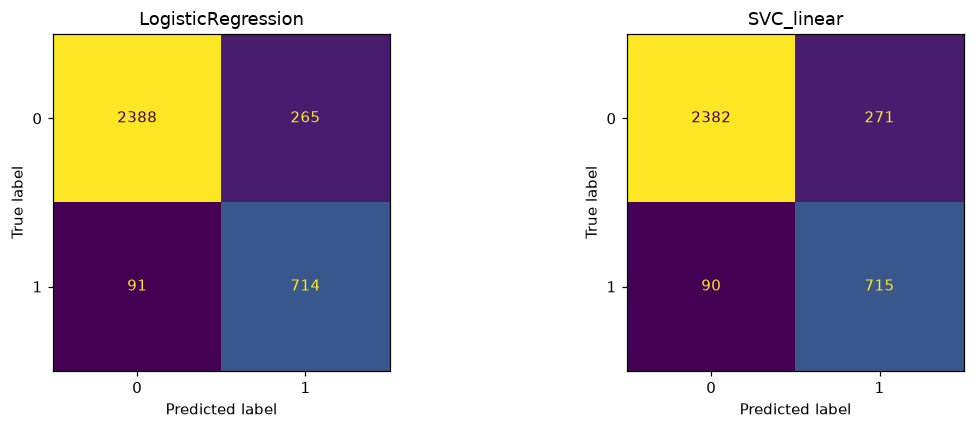

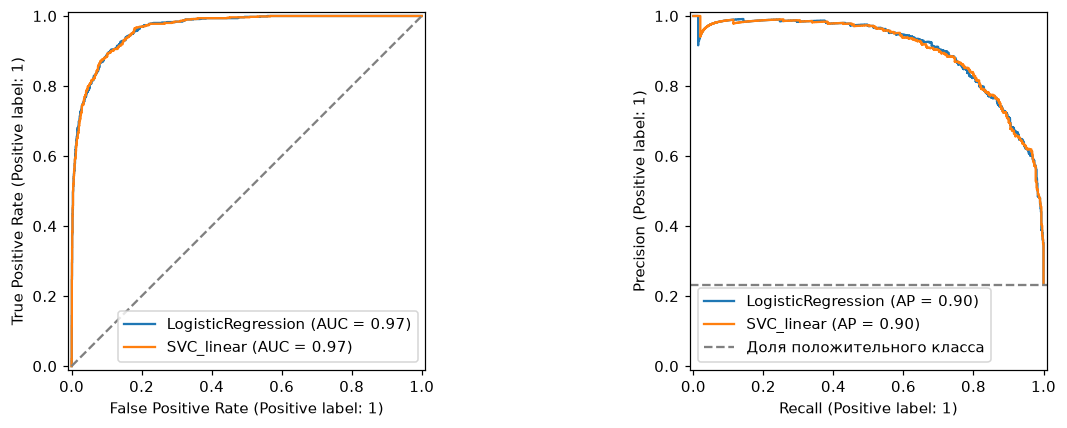

In [4]:
svm_search=fit_search('SVC_linear',SVC(kernel='linear',class_weight='balanced',cache_size=512,
    probability=False,tol=1e-3,random_state=SEED))
rows=[]
for weights in [None,'balanced']:
    m=clone(svm_search.best_estimator_).set_params(model__class_weight=weights)
    scores=cross_validate(m,X_train,y_train,cv=folds,n_jobs=2,error_score='raise',
        scoring={'balanced_accuracy':'balanced_accuracy','precision':'precision','recall':'recall'})
    rows.append({'class_weight':str(weights),**{k:v.mean() for k,v in scores.items() if k.startswith('test_')}})
weight_table=pd.DataFrame(rows); display(weight_table)
weight_table.to_csv(OUT/'svm_class_weight_cv.csv',index=False)
evaluate('SVC_linear',svm_search.best_estimator_)
metrics=pd.DataFrame(RESULTS).T
metrics.to_csv(OUT/'classification_metrics.csv'); display(metrics.round(4))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,(name,m) in zip(axes,MODELS.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,m.predict(X_test),ax=ax,colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig(OUT/'confusion_matrices.png'); plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,m in MODELS.items():
    score=m.decision_function(X_test)
    RocCurveDisplay.from_predictions(y_test,score,name=name,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test,score,name=name,ax=axes[1])
axes[0].plot([0,1],[0,1],'--',color='gray')
axes[1].axhline(y_test.mean(),ls='--',color='gray',label='Доля положительного класса')
axes[1].legend(); plt.tight_layout(); plt.savefig(OUT/'roc_pr.png'); plt.show()

In [5]:
r=RESULTS['SVC_linear']; delta=r['balanced_accuracy']-RESULTS['LogisticRegression']['balanced_accuracy']
display(Markdown(f"**Вывод 2.** По CV выбран C={svm_search.best_params_['model__C']}. "
    f"SVC на test: balanced accuracy **{r['balanced_accuracy']:.3f}**, F1 **{r['f1']:.3f}**, ROC AUC **{r['roc_auc']:.3f}**. "
    f"Разница balanced accuracy с LogisticRegression {delta:+.4f}. "
    "Один hold-out не доказывает статистическое превосходство. Обе границы линейны в преобразованном пространстве, "
    "но функции потерь различны. Таблица class_weight показывает обмен precision/recall при изменении штрафов на CV."))

**Вывод 2.** По CV выбран C=1.0. SVC на test: balanced accuracy **0.893**, F1 **0.798**, ROC AUC **0.965**. Разница balanced accuracy с LogisticRegression -0.0005. Один hold-out не доказывает статистическое превосходство. Обе границы линейны в преобразованном пространстве, но функции потерь различны. Таблица class_weight показывает обмен precision/recall при изменении штрафов на CV.

<font color='DarkOrange'>**Задание 3 [баллов: 6]:**</font>

1. Многоклассовая классификация. Дайте определения для подходов: микро, макро, взвешенный, пообъктный. Выполните расчёты вручную для слайда 43 (на примере любых 3 промежуточных AUC ROC, поясните, как из промежуточных характеристик получаются 4 финальных). В рамках детализации ОЦИФРУЙТЕ ROC: в Excel, отрисуйте линиями в Word или отрисуйте отдельными отрезками Python-кодом (не используйте готовые функции для ROC).
[баллов: 2]

2. Для одного из кейсов (одного класса) введите три порога бинаризации так, чтоб получились различные accuracy, recall, precision. Вычислите эти метрики вручную и сопроводите визуализацией расчёта для recall и precision (см пример из лекции с окружностями разных цветов и радиусов). По трём парам (precision, recall) постройте эскиз PR-кривой. [баллов: 2]

3. Сделайте выводы по результатам расчётом AUC ROC для многоклассовой классификации (какой вариант лучше, почему, объясните падение AUC ROC при переходе к многоклассовым). [баллов: 1]

4. В каких кейсах/доменах следует применять те или иные варианты? Запишите выводы. [баллов: 1]

**Часть Романа Пивоварова. Задания 3.1–3.4 здесь не выполнены.** При объединении вставить его ячейки в этот раздел.

<font color='DarkOrange'>**Задание 4 [баллов: 2]:**</font>

Исследуйте вопрос выбросов/новизны для данных в вашем датасете с использованием OneClassSVM (дайте краткую теоретическую характеристику, используйте готовые решения для получения результатов, сделайте выводы)

Материалы:
1) https://scikit-learn.ru/stable/modules/outlier_detection.html,
2) https://alexanderdyakonov.wordpress.com/, Поиск аномалий

### OneClassSVM: теория и постановка
OneClassSVM строит область типичных наблюдений, RBF-ядро позволяет нелинейную границу. predict=+1 означает внутри области, −1 — кандидат в аномалии; decision_function<0 — вне области.
`nu` — верхняя граница доли ошибок обучения и нижняя граница доли опорных векторов (с учётом численной точности), **не гарантированная доля аномалий на test**. `gamma='scale'` задаёт масштаб RBF по размерности и дисперсии входа.
Отдельная unsupervised-задача: используем log цены, log площади, число санузлов, год и парковку. Цена допустима именно здесь и не передаётся в классификаторы. Категории исключены, чтобы редкий город не определял расстояние, но из-за этого региональная норма цены не учитывается.
Предобработка обучается только на train. Сравним nu=0.01,0.05,0.10; для подробного анализа **заранее** выбираем 0.05, не оптимизируем на test. Train — поиск выбросов, test — проверка необычности новых наблюдений. Train не проверен экспертом, поэтому это не строгий novelty detection с гарантированно чистой нормой. Нет истинной разметки аномалий: нельзя честно вычислить precision/recall детектора.

,nu,train_outlier_share,test_outlier_share,support_share
0,0.01,0.010411,0.013013,0.013664
1,0.05,0.050174,0.054367,0.051403
2,0.10,0.099769,0.096298,0.100925


,Price,LivingArea,NumberOfBathrooms,ConstructionYear,Parking,District,City,score,outlier
178642,1395000.0,263.0,10.0,2016.0,0.0,Leiria,Leiria,-48.005654,True
152750,2350000.0,377.0,8.0,2010.0,1.0,Lisboa,Lisboa,-42.233266,True
152935,270000.0,244.0,6.0,1951.0,0.0,Lisboa,Lisboa,-40.213449,True
154765,5125000.0,396.0,7.0,2026.0,0.0,Lisboa,Cascais,-37.192580,True
154714,5400000.0,328.0,7.0,2026.0,0.0,Lisboa,Cascais,-36.625196,True
145098,16000.0,120.0,2.0,1985.0,0.0,Faro,Albufeira,-35.724268,True
137801,468000.0,672.0,3.0,1995.0,0.0,Braga,Braga,-34.983640,True
153473,2200000.0,265.0,3.0,1913.0,0.0,Lisboa,Lisboa,-34.266604,True
144281,15900.0,45.0,1.0,1990.0,1.0,Faro,Albufeira,-33.631499,True
150541,695000.0,90.0,1.0,1900.0,1.0,Lisboa,Lisboa,-33.499311,True


,Price,LivingArea,NumberOfBathrooms,ConstructionYear,Parking
outlier,,,,,
False,339000.0,89.0,2.0,2001.0,0.0
True,437500.0,95.0,2.0,1996.0,0.0


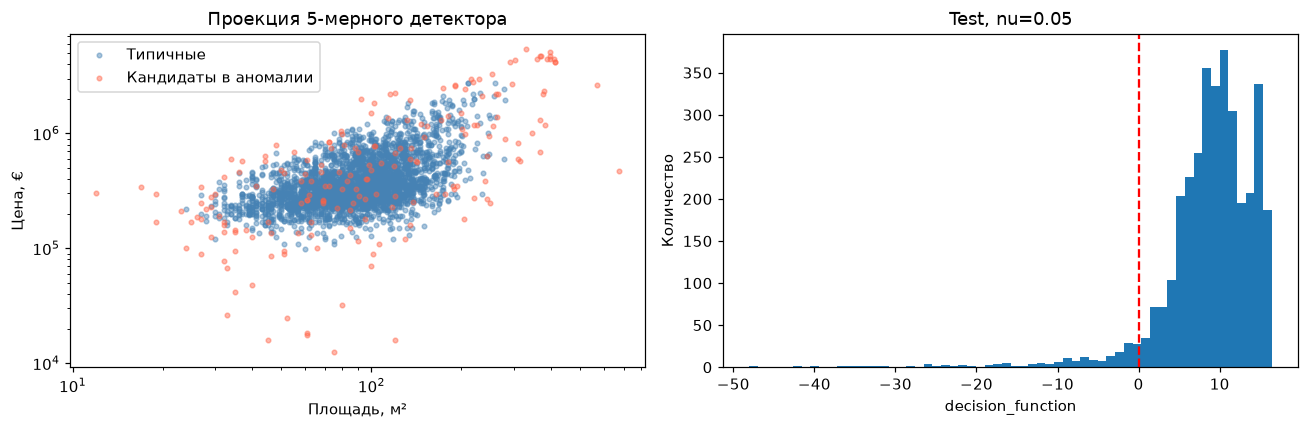

In [6]:
ANOM=['Price','LivingArea','NumberOfBathrooms','ConstructionYear','Parking']
def log_price_area(a):
    a=np.array(a,dtype=float,copy=True); a[:,:2]=np.log(a[:,:2]); return a
A_train,A_test=df.loc[train_idx,ANOM],df.loc[test_idx,ANOM]
anom_prep=Pipeline([('impute',SimpleImputer(strategy='median')),('log',FunctionTransformer(log_price_area)),('scale',StandardScaler())])
Z_train=anom_prep.fit_transform(A_train); Z_test=anom_prep.transform(A_test)
anom_models,rows={},[]
for nu in [.01,.05,.10]:
    detector=OneClassSVM(kernel='rbf',gamma='scale',nu=nu,cache_size=512).fit(Z_train)
    anom_models[nu]=detector
    rows.append({'nu':nu,'train_outlier_share':(detector.predict(Z_train)==-1).mean(),
        'test_outlier_share':(detector.predict(Z_test)==-1).mean(),'support_share':len(detector.support_)/len(Z_train)})
sensitivity=pd.DataFrame(rows); display(sensitivity)
sensitivity.to_csv(OUT/'oneclass_sensitivity.csv',index=False)
detector=anom_models[.05]
anomalies=df.loc[test_idx,ANOM+['District','City']].copy()
anomalies['score']=detector.decision_function(Z_test)
anomalies['outlier']=detector.predict(Z_test)==-1
anomalies.to_csv(OUT/'oneclass_test.csv',index_label='row_index')
display(anomalies.nsmallest(10,'score'))
display(anomalies.groupby('outlier')[ANOM].median())
fig,axes=plt.subplots(1,2,figsize=(12,4))
for flag,color,label in [(False,'steelblue','Типичные'),(True,'tomato','Кандидаты в аномалии')]:
    sub=anomalies[anomalies.outlier==flag]
    axes[0].scatter(sub.LivingArea,sub.Price,s=9,alpha=.45,c=color,label=label)
axes[0].set(xscale='log',yscale='log',xlabel='Площадь, м²',ylabel='Цена, €',title='Проекция 5-мерного детектора')
axes[0].legend(); axes[1].hist(anomalies.score,bins=60); axes[1].axvline(0,color='red',ls='--')
axes[1].set(xlabel='decision_function',ylabel='Количество',title='Test, nu=0.05')
plt.tight_layout(); plt.savefig(OUT/'oneclass.png'); plt.show()

In [7]:
worst=anomalies.nsmallest(1,'score').iloc[0]
display(Markdown(f"**Вывод 4.** При nu=0.05 отмечено **{anomalies.outlier.mean():.1%}** test "
    f"({anomalies.outlier.sum()} из {len(anomalies)}). Самый необычный объект: "
    f"{worst.Price:,.0f} €, {worst.LivingArea:g} м², санузлов {worst.NumberOfBathrooms:g}, "
    f"год {worst.ConstructionYear:g}, парковок {worst.Parking:g}, город {worst.City}. "
    "Это повод проверить объявление, а не доказательство ошибки. Проекция показывает только 2 из 5 координат, "
    "поэтому внешне обычная точка тоже может быть аномальной. Зависимость долей от nu — анализ чувствительности, "
    "не подбор оптимального nu без разметки. Автоматически удалять эти объекты из классификации нельзя: "
    "дорогие квартиры являются целевым классом. Нужны экспертная проверка и учёт региональных цен."))
assert all(np.isfinite(list(r.values())).all() for r in RESULTS.values())
assert np.isfinite(anomalies.score).all() and len(anomalies)==len(y_test)
print('CHECKS PASSED: disjoint split, no price in classifier features, finite metrics and anomaly scores.')

**Вывод 4.** При nu=0.05 отмечено **5.4%** test (188 из 3458). Самый необычный объект: 1,395,000 €, 263 м², санузлов 10, год 2016, парковок 0, город Leiria. Это повод проверить объявление, а не доказательство ошибки. Проекция показывает только 2 из 5 координат, поэтому внешне обычная точка тоже может быть аномальной. Зависимость долей от nu — анализ чувствительности, не подбор оптимального nu без разметки. Автоматически удалять эти объекты из классификации нельзя: дорогие квартиры являются целевым классом. Нужны экспертная проверка и учёт региональных цен.

CHECKS PASSED: disjoint split, no price in classifier features, finite metrics and anomaly scores.


### Источники
- [Данные Kaggle](https://www.kaggle.com/datasets/luvathoms/portugal-real-estate-2024).
- Шаблон преподавателя от 10.10.2026, исходник в materials/Lab3.ipynb.
- [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).
- [Поиск выбросов и новизны](https://scikit-learn.org/stable/modules/outlier_detection.html).
Полная совместная ЛР3 требует задания 3 и устной защиты.